In [4]:
from pathlib import Path
import pandas as pd

data_path = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science\project\code_project\data\Project_Data\external_urls.json"
)

df_urls = pd.read_json(data_path)

print(f"Righe: {df_urls.shape[0]:,}")
print(f"Colonne: {df_urls.shape[1]}")

df_urls.head()

Righe: 252,877
Colonne: 4


,id_ext_url,url,truth_id,url_id
0,1780,https://www.supremecourt.gov/opinions/21pdf/19...,3207,1780
1,1780,https://www.supremecourt.gov/opinions/21pdf/19...,41909,1780
2,1780,https://www.supremecourt.gov/opinions/21pdf/19...,80108,1780
3,1780,https://www.supremecourt.gov/opinions/21pdf/19...,251504,1780
4,1780,https://www.supremecourt.gov/opinions/21pdf/19...,272831,1780


In [5]:
riepilogo = pd.DataFrame({
    "tipo": df_urls.dtypes,
    "valori_mancanti": df_urls.isna().sum(),
    "valori_distinti": df_urls.nunique()
})

riepilogo

,tipo,valori_mancanti,valori_distinti
id_ext_url,int64,0,173944
url,str,0,173944
truth_id,int64,0,247461
url_id,int64,0,173944


In [6]:
print("Exact duplicate rows:",
      df_urls.duplicated().sum())

print("Duplicate post–URL pairs:",
      df_urls.duplicated(subset=["truth_id", "url_id"]).sum())

print("Rows where id_ext_url differs from url_id:",
      (df_urls["id_ext_url"] != df_urls["url_id"]).sum())

Exact duplicate rows: 5
Duplicate post–URL pairs: 5
Rows where id_ext_url differs from url_id: 0


In [7]:
duplicate_rows = df_urls[
    df_urls.duplicated(keep=False)
].sort_values(by=["truth_id", "url_id"])

duplicate_rows

,id_ext_url,url,truth_id,url_id
217291,149581,https://rumble.com/embed/vsw2j6/,115732,149581
217292,149581,https://rumble.com/embed/vsw2j6/,115732,149581
32020,17103,https://www.vvdailypress.com/story/news/2022/0...,115745,17103
32021,17103,https://www.vvdailypress.com/story/news/2022/0...,115745,17103
217295,149583,https://rumble.com/embed/vsej62/,115754,149583
217296,149583,https://rumble.com/embed/vsej62/,115754,149583
33962,18960,https://thefederalist.com/2022/02/14/special-c...,115755,18960
33963,18960,https://thefederalist.com/2022/02/14/special-c...,115755,18960
10780,1761,https://babylonbee.com/news/brilliant-la-schoo...,115757,1761
10781,1761,https://babylonbee.com/news/brilliant-la-schoo...,115757,1761


In [8]:
df_urls_clean = df_urls.drop_duplicates().copy()

print("Original rows:", len(df_urls))
print("Cleaned rows:", len(df_urls_clean))
print("Removed duplicates:", len(df_urls) - len(df_urls_clean))
print("Remaining exact duplicates:", df_urls_clean.duplicated().sum())

Original rows: 252877
Cleaned rows: 252872
Removed duplicates: 5
Remaining exact duplicates: 0


In [9]:
urls_per_id = df_urls_clean.groupby("url_id")["url"].nunique()
ids_per_url = df_urls_clean.groupby("url")["url_id"].nunique()

print("URL IDs associated with multiple URLs:",
      (urls_per_id > 1).sum())

print("URLs associated with multiple URL IDs:",
      (ids_per_url > 1).sum())

URL IDs associated with multiple URLs: 0
URLs associated with multiple URL IDs: 0


In [10]:
from urllib.parse import urlsplit

def is_valid_url(value):
    if not isinstance(value, str) or not value:
        return False

    if any(character.isspace() for character in value):
        return False

    try:
        parsed = urlsplit(value)
        parsed.port  # Check for malformed port numbers

        return (
            parsed.scheme.lower() in {"http", "https"}
            and bool(parsed.hostname)
        )
    except ValueError:
        return False

df_urls_clean["is_valid_url"] = df_urls_clean["url"].map(is_valid_url)

print("URLs failing syntax checks:",
      (~df_urls_clean["is_valid_url"]).sum())

df_urls_clean.loc[
    ~df_urls_clean["is_valid_url"],
    ["url_id", "url", "truth_id"]
]

URLs failing syntax checks: 6


,url_id,url,truth_id
131989,86769,gracechong,322988
154701,119437,thomaswolfe,716921
155198,119478,PatriotPlymouth2,717643
155694,119561,TexanSeekingTruth,718755
157700,106724,Moon52,549862
185378,140667,DanMeyerswords,856834


In [11]:
urls_to_review = df_urls_clean.loc[
    ~df_urls_clean["is_valid_url"]
].copy()

df_urls_valid = df_urls_clean.loc[
    df_urls_clean["is_valid_url"]
].copy()

print("Rows with valid URL syntax:", len(df_urls_valid))
print("Rows requiring review:", len(urls_to_review))

print(
    urls_to_review[["url_id", "url", "truth_id"]]
    .to_string(index=False)
)

Rows with valid URL syntax: 252866
Rows requiring review: 6
 url_id               url  truth_id
  86769        gracechong    322988
 119437       thomaswolfe    716921
 119478  PatriotPlymouth2    717643
 119561 TexanSeekingTruth    718755
 106724            Moon52    549862
 140667    DanMeyerswords    856834


In [12]:
def extract_domain(url):
    hostname = urlsplit(url).hostname.lower()
    return hostname.removeprefix("www.")

df_urls_valid["domain"] = df_urls_valid["url"].map(extract_domain)

domain_summary = (
    df_urls_valid.groupby("domain")
    .agg(
        associations=("url_id", "size"),
        unique_urls=("url_id", "nunique"),
        unique_posts=("truth_id", "nunique")
    )
    .sort_values("associations", ascending=False)
)

print("Unique domains:", len(domain_summary))

domain_summary.head(15)

Unique domains: 5162


,associations,unique_urls,unique_posts
domain,,,
rumble.com,67263,40869,66300
thegatewaypundit.com,11036,5687,11018
justthenews.com,9839,4920,9837
foxsports.com,6669,6618,6669
breitbart.com,6244,3150,6243
gamespot.com,6054,6043,6054
t.me,5277,4760,5255
youtu.be,5007,4007,4984
hiphopdx.com,4880,4849,4880


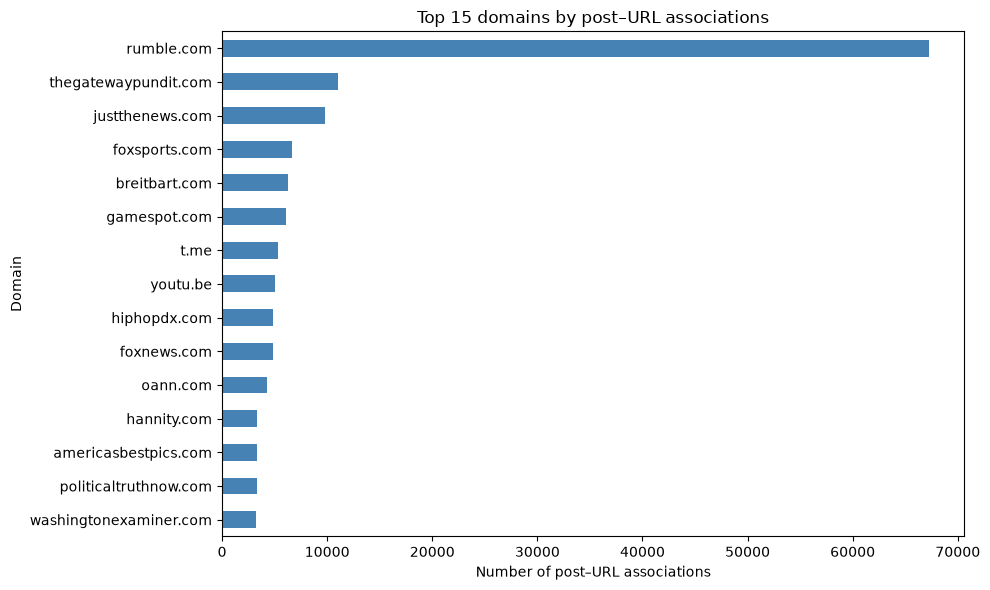

In [13]:
import matplotlib.pyplot as plt

top_domains = domain_summary.head(15)

ax = top_domains["associations"].sort_values().plot.barh(
    figsize=(10, 6),
    color="steelblue"
)

ax.set_title("Top 15 domains by post–URL associations")
ax.set_xlabel("Number of post–URL associations")
ax.set_ylabel("Domain")

plt.tight_layout()
plt.show()

In [15]:
urls_per_post = (
    df_urls_valid.groupby("truth_id")["url_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("URL count per post — descriptive statistics:")
display(
    urls_per_post.describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame("unique_urls")
)

print("Posts with more than one valid URL:", (urls_per_post > 1).sum())

print("\nTop 10 posts by number of unique URLs:")
display(urls_per_post.head(10).to_frame("unique_urls"))

URL count per post — descriptive statistics:


,unique_urls
count,247455.000000
mean,1.021867
std,0.167766
min,1.000000
50%,1.000000
90%,1.000000
95%,1.000000
99%,2.000000
max,9.000000


Posts with more than one valid URL: 4813

Top 10 posts by number of unique URLs:


,unique_urls
truth_id,
700428,9
4495,8
936671,8
748992,8
114775,7
513361,7
276080,6
752441,6
179749,5


In [16]:
max_urls_post_id = urls_per_post.idxmax()

print("Post ID:", max_urls_post_id)
print("Number of unique URLs:", urls_per_post.max())

print(
    df_urls_valid.loc[
        df_urls_valid["truth_id"] == max_urls_post_id,
        ["url_id", "url", "domain"]
    ].to_string(index=False)
)

Post ID: 700428
Number of unique URLs: 9
 url_id                          url domain
  87984 https://t.me/project_veritas   t.me
  88051      https://t.me/PepeMatter   t.me
 118372      https://t.me/WeTheMedia   t.me
 118373   https://t.me/praying_medic   t.me
 118374   https://t.me/DineshJDSouza   t.me
 118375   https://t.me/CandaceOnFire   t.me
 118376    https://t.me/SidneyPowell   t.me
 118377  https://t.me/DavidJHarrisJr   t.me
 118378 https://t.me/DanScavinoForce   t.me


In [17]:
url_text = df_urls_clean["url"].astype("string")

url_format_checks = pd.Series({
    "Empty or whitespace-only URLs": url_text.str.strip().eq("").sum(),
    "URLs with leading or trailing whitespace": (
        url_text.ne(url_text.str.strip()).sum()
    ),
    "URLs containing whitespace": (
        url_text.str.contains(r"\s", regex=True, na=False).sum()
    )
})

display(url_format_checks.to_frame("row_count"))

,row_count
Empty or whitespace-only URLs,0
URLs with leading or trailing whitespace,0
URLs containing whitespace,0


In [18]:
df_urls_valid["url_length"] = df_urls_valid["url"].str.len()

display(
    df_urls_valid["url_length"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .to_frame("url_length")
)

print("Top 5 longest URLs:")

print(
    df_urls_valid
    .drop_duplicates(subset=["url"])
    .nlargest(5, "url_length")[["url", "url_length"]]
    .to_string(index=False)
)

,url_length
count,252866.000000
mean,85.414678
std,49.581685
min,13.000000
50%,85.000000
90%,146.000000
95%,174.000000
99%,226.000000
max,606.000000


Top 5 longest URLs:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           url  url_length
https://www.malwarebytes.com/blog/news/2022/08/twitter-under-scrutiny-after-former-executive-turns-whistleblower?utm_source=blueshift&amp;utm_medium=email&amp;utm_campaign=b2c_pro_oth_august_29th_2022_weekly_newsletter_166146363119&amp;utm_content=Keep_Reading_1&amp;bsft_aaid=18a8abbd-b7b6-422b-8352-283554e9475a&amp;bsft_eid=c4e83a45-d0c0-f179-60a4-f8e947e0d5

In [19]:
id_columns = ["id_ext_url", "url_id", "truth_id"]

id_checks = pd.DataFrame({
    "missing_values": df_urls_clean[id_columns].isna().sum(),
    "zero_values": df_urls_clean[id_columns].eq(0).sum(),
    "negative_values": df_urls_clean[id_columns].lt(0).sum(),
    "minimum_value": df_urls_clean[id_columns].min(),
    "maximum_value": df_urls_clean[id_columns].max()
})

display(id_checks)

,missing_values,zero_values,negative_values,minimum_value,maximum_value
id_ext_url,0,0,0,3,173950
url_id,0,0,0,3,173950
truth_id,0,0,0,21,978127


In [20]:
truths_path = data_path.parent / "truths.csv"

df_truths_preview = pd.read_csv(truths_path, nrows=5)

print("Truths dataset columns:")
print(df_truths_preview.columns.tolist())

display(df_truths_preview)

Truths dataset columns:
['id', 'timestamp', 'time_scraped', 'is_retruth', 'is_reply', 'author', 'like_count', 'retruth_count', 'reply_count', 'text', 'external_id', 'url', 'truth_retruthed']


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
0,703265,2022-05-14 00:00:00,2022-11-01 15:48:16.829245,t,f,2247.0,0,0,0,Q+ BE READY ANONS - PUBLIC AWAKENING COMING - ...,108351978111014587,https://truthsocial.com/@jweimer39/posts/10835...,1043583.0
1,807614,2022-03-27 00:00:00,2022-11-23 10:54:36.865046,t,f,20054.0,0,0,0,Enough is enough! RETRUTH,108040697775316106,https://truthsocial.com/@CeceBloomwood/posts/1...,988567.0
2,807615,2022-03-29 00:00:00,2022-11-23 10:55:11.613249,t,f,20054.0,0,0,0,https://justthenews.com/politics-policy/all-th...,108040478595657472,https://truthsocial.com/@CeceBloomwood/posts/1...,1002825.0
3,807618,2022-03-29 00:00:00,2022-11-23 10:56:29.134825,t,f,20054.0,0,0,0,https://t.me/realx22report/6729,108040420546204424,https://truthsocial.com/@CeceBloomwood/posts/1...,989757.0
4,807619,2022-03-29 00:00:00,2022-11-23 10:57:20.028953,f,t,20054.0,0,0,0,@CeceBloomwood,108040224733670356,https://truthsocial.com/@CeceBloomwood/posts/1...,-1.0


In [21]:
truth_ids = pd.read_csv(truths_path, usecols=["id"])["id"]

missing_truth_mask = ~df_urls_clean["truth_id"].isin(truth_ids)

orphan_url_rows = df_urls_clean.loc[missing_truth_mask].copy()

print("URL rows referencing missing posts:", len(orphan_url_rows))
print(
    "Distinct post IDs missing from truths.csv:",
    orphan_url_rows["truth_id"].nunique()
)

display(orphan_url_rows[["truth_id", "url_id", "url"]].head(10))

URL rows referencing missing posts: 32173
Distinct post IDs missing from truths.csv: 30816


,truth_id,url_id,url
1,41909,1780,https://www.supremecourt.gov/opinions/21pdf/19...
34,120,10,https://hannity.com/media-room/ben-on-the-mend...
41,125,15,https://hannity.com/media-room/jimmy-eat-crow-...
58,136,26,https://hannity.com/media-room/constitutional-...
59,494771,26,https://hannity.com/media-room/constitutional-...
60,456204,26,https://hannity.com/media-room/constitutional-...
61,662908,26,https://hannity.com/media-room/constitutional-...
63,138,28,https://hannity.com/media-room/rand-slam-watch...
71,143,33,https://hannity.com/media-room/dead-wrong-manc...
72,631219,33,https://hannity.com/media-room/dead-wrong-manc...


In [22]:
retruth_ids = pd.read_csv(
    truths_path,
    usecols=["truth_retruthed"]
)["truth_retruthed"]

retruth_ids = pd.to_numeric(retruth_ids, errors="coerce")
retruth_ids = retruth_ids.dropna()
retruth_ids = retruth_ids[retruth_ids > 0]

orphan_post_ids = orphan_url_rows["truth_id"].drop_duplicates()

referenced_as_retruth = orphan_post_ids.isin(retruth_ids)

print("Missing post IDs referenced in truth_retruthed:",
      referenced_as_retruth.sum())

print("Missing post IDs absent from both columns:",
      (~referenced_as_retruth).sum())

Missing post IDs referenced in truth_retruthed: 0
Missing post IDs absent from both columns: 30816


In [23]:
df_urls_clean["post_exists_in_truths"] = (
    df_urls_clean["truth_id"].isin(truth_ids)
)

df_urls_valid["post_exists_in_truths"] = (
    df_urls_valid["truth_id"].isin(truth_ids)
)

reference_summary = (
    df_urls_clean["post_exists_in_truths"]
    .value_counts()
    .rename_axis("post_exists_in_truths")
    .to_frame("associations")
)

reference_summary["percentage"] = (
    reference_summary["associations"] / len(df_urls_clean) * 100
).round(2)

display(reference_summary)

,associations,percentage
post_exists_in_truths,,
True,220699,87.28
False,32173,12.72


In [24]:
urls_to_review["post_exists_in_truths"] = (
    urls_to_review["truth_id"].isin(truth_ids)
)

display(
    urls_to_review[
        ["url_id", "url", "truth_id", "post_exists_in_truths"]
    ]
)

,url_id,url,truth_id,post_exists_in_truths
131989,86769,gracechong,322988,True
154701,119437,thomaswolfe,716921,True
155198,119478,PatriotPlymouth2,717643,False
155694,119561,TexanSeekingTruth,718755,True
157700,106724,Moon52,549862,True
185378,140667,DanMeyerswords,856834,True
